<a href="https://colab.research.google.com/github/zhousiyu666-ctrl/TTTC3213-Assignment-1/blob/main/Assignment_1_Data_Profiling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1: Data Profiling

**Name and matric number:**

- A205746 ZHOU SIYU
- A204198 WANG ZHENYU
- A199947 SUN SHIXUAN
- A206378 HUANG JUNXIONG

## Scenario

Our project compares Spotify music trends in Malaysia and globally. Before comparing songs and rankings, we need to check for missing values, unusual values and other data quality issues.

## Data source

We downloaded the [Spotify Charts dataset by Dhruvildave](https://www.kaggle.com/datasets/dhruvildave/spotify-charts) from Kaggle and extracted `charts.csv` from the ZIP file. This notebook reads the full file and selects Malaysia and Global records for our project.

The CSV file is also available here: [Download charts.csv from Google Drive](https://drive.google.com/file/d/1Pb82Fz7TgHKbK_OabpDEaPZMqk1oaGVH/view?usp=drive_link).

## How to run

1. Download `charts.csv` from the Google Drive link above or from Kaggle.
2. Upload the file to Google Drive in `My Drive/TTTC3213/Project/`.
3. Open this notebook in Google Colab and run all cells.
4. Allow access to Google Drive when prompted.

In [11]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')  # authorize access when prompted
    DATA_PATH = Path('/content/drive/MyDrive/TTTC3213/Project/charts.csv')
else:
    DATA_PATH = Path('charts.csv')  # CSV beside the notebook

CHUNK_SIZE = 250_000
assert DATA_PATH.is_file(), f'File not found: {DATA_PATH}. Check the README/data location instructions.'
print('Source:', DATA_PATH.resolve())
print('Bytes:', DATA_PATH.stat().st_size)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Source: /content/drive/MyDrive/TTTC3213/Project/charts.csv
Bytes: 3483476388


## 1. Read the data
The file is too large to load all at once, so we read it in chunks. We keep the Malaysia and Global records because these are the two regions used in our project.

In [12]:
parts = []
source_rows = 0
for chunk in pd.read_csv(DATA_PATH, encoding='utf-8', dtype=str, keep_default_na=False, chunksize=CHUNK_SIZE):
    source_rows += len(chunk)
    parts.append(chunk.loc[chunk['region'].isin(['Malaysia', 'Global'])].copy())
raw = pd.concat(parts, ignore_index=True).replace(r'^\s*$', pd.NA, regex=True)
del parts
print(f'Full source rows scanned: {source_rows:,}')
print(f'Project rows retained: {len(raw):,}')
display(raw.head())
display(raw.groupby(['region', 'chart'], dropna=False).size().rename('rows').to_frame())

Full source rows scanned: 26,173,514
Project rows retained: 901,126


,title,rank,date,artist,url,region,chart,trend,streams
0,Starboy,1,2017-01-01,"The Weeknd, Daft Punk",https://open.spotify.com/track/5aAx2yezTd8zXrk...,Global,top200,SAME_POSITION,3135625
1,Closer,2,2017-01-01,"The Chainsmokers, Halsey",https://open.spotify.com/track/7BKLCZ1jbUBVqRi...,Global,top200,SAME_POSITION,3015525
2,Let Me Love You,3,2017-01-01,"DJ Snake, Justin Bieber",https://open.spotify.com/track/4pdPtRcBmOSQDlJ...,Global,top200,MOVE_UP,2545384
3,Rockabye (feat. Sean Paul & Anne-Marie),4,2017-01-01,Clean Bandit,https://open.spotify.com/track/5knuzwU65gJK7IF...,Global,top200,MOVE_DOWN,2356604
4,One Dance,5,2017-01-01,"Drake, WizKid, Kyla",https://open.spotify.com/track/1xznGGDReH1oQq0...,Global,top200,SAME_POSITION,2259887


rows
region   chart          
Global   top200   362182
         viral50   89611
Malaysia top200   358390
         viral50   90943

## 2. Check missing values
First, we count the missing values in each column. Then we compare missing `streams` values for the two chart types.

,missing,percent
title,0,0.000000
rank,0,0.000000
date,0,0.000000
artist,0,0.000000
url,0,0.000000
region,0,0.000000
chart,0,0.000000
trend,0,0.000000
streams,180554,20.036488


,rows,missing,missing_percent
chart,,,
top200,720572,0,0.0
viral50,180554,180554,100.0


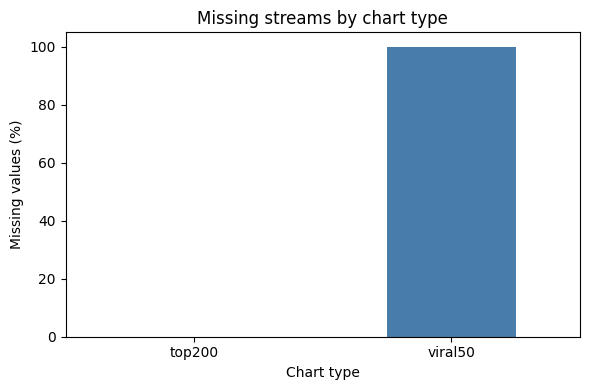

In [13]:
missing = pd.DataFrame({'missing': raw.isna().sum(), 'percent': raw.isna().mean()*100})
display(missing)
missing_by_chart = raw.groupby('chart', dropna=False)['streams'].agg(rows='size', missing=lambda s: s.isna().sum())
missing_by_chart['missing_percent'] = 100 * missing_by_chart['missing'] / missing_by_chart['rows']
display(missing_by_chart)
ax = missing_by_chart['missing_percent'].plot.bar(color='#477da8', figsize=(6,4), rot=0)
ax.set(title='Missing streams by chart type', xlabel='Chart type', ylabel='Missing values (%)', ylim=(0,105))
plt.tight_layout(); plt.show()

All missing `streams` values in our project data are from `viral50`. We keep these rows and leave the values missing because a missing value does not mean zero streams. For questions about streaming counts, we use only records with a count. We do not know from this file alone why the viral chart values are missing.

## 3. Check data types, invalid values and duplicates
We convert dates and numbers to suitable types and check the results. We expect `top200` ranks to be between 1 and 200 and `viral50` ranks between 1 and 50. This is an assumption based on the chart names, so values outside these ranges need checking against the original source. We also check for identical rows and repeated region, chart, date and song URL combinations.

In [14]:
clean = raw.copy()
clean['date_parsed'] = pd.to_datetime(clean['date'], format='%Y-%m-%d', errors='coerce')
clean['rank_numeric'] = pd.to_numeric(clean['rank'], errors='coerce')
clean['streams_numeric'] = pd.to_numeric(clean['streams'], errors='coerce')
clean['streams_missing'] = clean['streams'].isna()
clean['invalid_date'] = clean['date_parsed'].isna()
clean['invalid_streams'] = clean['streams'].notna() & (clean['streams_numeric'].isna() | (clean['streams_numeric'] < 0))
limits = clean['chart'].map({'top200': 200, 'viral50': 50})
r = clean['rank_numeric']
clean['rank_out_of_expected_range'] = r.isna() | limits.isna() | (r < 1) | (r % 1 != 0) | (r > limits)
exact_duplicates = raw.duplicated()
key = ['region', 'chart', 'date', 'url']
key_duplicates = raw.duplicated(subset=key, keep=False)
display(pd.Series({'invalid date': clean.invalid_date.sum(), 'invalid streams': clean.invalid_streams.sum(), 'rank outside assumed range': clean.rank_out_of_expected_range.sum(), 'exact duplicates after first': exact_duplicates.sum(), 'rows sharing candidate key': key_duplicates.sum()}).to_frame('rows'))
display(clean.loc[clean.rank_out_of_expected_range, ['date','region','chart','rank','title']].head(10))
print('Date range:', clean.date_parsed.min(), 'to', clean.date_parsed.max())

,rows
invalid date,0
invalid streams,0
rank outside assumed range,31
exact duplicates after first,0
rows sharing candidate key,0


,date,region,chart,rank,title
441549,2019-11-29,Global,viral50,51,You Calling My Name
491121,2018-12-01,Global,viral50,51,Me Voy
491765,2018-12-02,Global,viral50,51,Quem Me Dera
492571,2018-12-03,Global,viral50,51,Why Haven't I Met You?
494221,2018-12-04,Global,viral50,51,Imposible
494671,2018-12-05,Global,viral50,51,Veneno
495221,2018-12-06,Global,viral50,51,Armed And Dangerous
496121,2018-12-07,Global,viral50,51,Happy Now
497172,2018-12-08,Global,viral50,51,"Kill 'Em With Success (with ScHoolboy Q, 2 Cha..."
497952,2018-12-09,Global,viral50,51,Quem Me Dera


Date range: 2017-01-01 00:00:00 to 2021-12-31 00:00:00


In [15]:
# Remove only exact duplicate rows; keep the first copy. Preserve all flags.
clean = clean.loc[~exact_duplicates].copy()
rank_ready = clean.loc[~clean.invalid_date & ~clean.rank_out_of_expected_range].copy()
stream_ready = clean.loc[~clean.invalid_date & ~clean.invalid_streams & clean.streams_numeric.notna()].copy()
print(f'Rows before: {len(raw):,}; after exact deduplication: {len(clean):,}')
print(f'Rows eligible for rank analysis: {len(rank_ready):,}')
print(f'Rows eligible for stream analysis: {len(stream_ready):,}')
assert clean['streams_missing'].sum() == clean['streams_numeric'].isna().sum() - (clean['streams'].notna() & clean['streams_numeric'].isna()).sum()
assert not rank_ready.rank_out_of_expected_range.any()
assert stream_ready.streams_numeric.notna().all()

Rows before: 901,126; after exact deduplication: 901,126
Rows eligible for rank analysis: 901,095
Rows eligible for stream analysis: 720,572


## 4. Check outliers
We use the IQR method to flag unusually high stream counts, separately for Malaysia and Global. A high count may be real for a popular song, so we keep these records instead of deleting them. The second chart shows the distribution on a log scale.

,Q1,Q3,IQR,upper_fence
region,,,,
Global,718916.25,1382879.5,663963.25,2378824.375
Malaysia,6270.00,12508.0,6238.00,21865.000


,rows,flagged,proportion
region,,,
Global,362182,30002,0.082837
Malaysia,358390,33386,0.093156


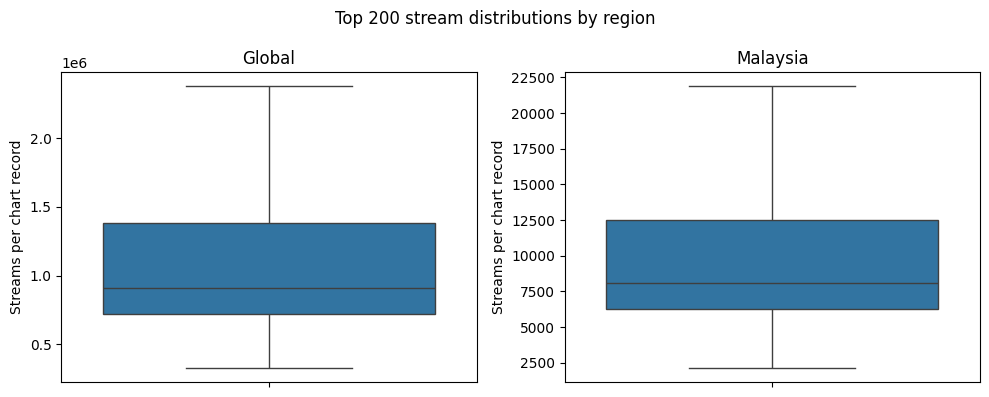

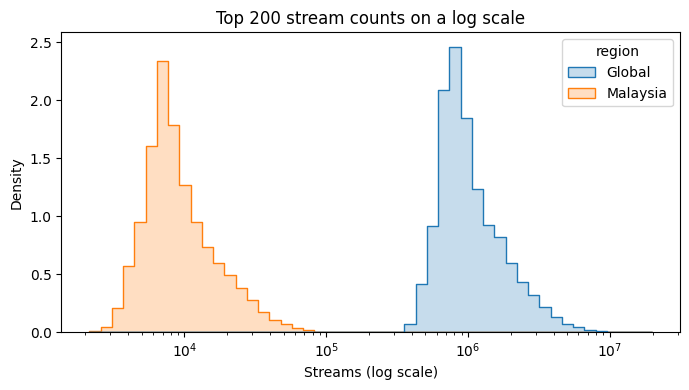

In [16]:
# Select Top 200 records with available stream counts
top = stream_ready.loc[
    stream_ready['chart'].eq('top200')
].copy()

# Calculate Q1, Q3 and IQR for each region
quartiles = (
    top.groupby('region')['streams_numeric']
    .quantile([0.25, 0.75])
    .unstack()
)

quartiles.columns = ['Q1', 'Q3']
quartiles['IQR'] = quartiles['Q3'] - quartiles['Q1']
quartiles['upper_fence'] = quartiles['Q3'] + 1.5 * quartiles['IQR']

# Flag unusually high stream counts
top['upper_fence'] = top['region'].map(quartiles['upper_fence'])
top['high_iqr_outlier'] = top['streams_numeric'] > top['upper_fence']

# Show thresholds and number of flagged records
display(quartiles)

display(
    top.groupby('region')['high_iqr_outlier'].agg(
        rows='size',
        flagged='sum',
        proportion='mean'
    )
)

# Draw separate boxplots so both distributions are visible
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, region in zip(axes, ['Global', 'Malaysia']):
    region_data = top[top['region'] == region]

    sns.boxplot(
        data=region_data,
        y='streams_numeric',
        showfliers=False,
        ax=ax
    )

    ax.set_title(region)
    ax.set_ylabel('Streams per chart record')

plt.suptitle('Top 200 stream distributions by region')
plt.tight_layout()
plt.show()

# Show the distributions on a log scale
fig, ax = plt.subplots(figsize=(7, 4))

sns.histplot(
    data=top,
    x='streams_numeric',
    hue='region',
    bins=50,
    element='step',
    stat='density',
    common_norm=False,
    log_scale=(True, False),
    ax=ax
)

ax.set(
    title='Top 200 stream counts on a log scale',
    xlabel='Streams (log scale)',
    ylabel='Density'
)

plt.tight_layout()
plt.show()

## 5. Coverage, privacy and bias
The columns contain song titles and artist names, but no obvious listener names, email addresses or user IDs. Some artist names identify real people, and we should still respect the dataset's licence.

The data covers charting songs, not every song listened to on Spotify. Global also includes Malaysia, and the two regions have different numbers of listeners, so their total stream counts should be compared carefully. Their dates do not cover exactly the same period. Before making weekly comparisons, we should check for missing dates and use a clearly defined week; a weekly summary made from daily records is not necessarily an official weekly chart.

In [17]:
coverage = clean.groupby(['region','chart'])['date_parsed'].agg(first='min', last='max', days='nunique', rows='size')
display(coverage)
daily = clean.groupby(['region','chart','date_parsed']).size().rename('records').reset_index()
display(daily.groupby(['region','chart'])['records'].agg(min='min', median='median', max='max'))

first       last  days    rows
region   chart                                      
Global   top200  2017-01-01 2021-12-20  1811  362182
         viral50 2017-01-01 2021-12-31  1794   89611
Malaysia top200  2017-01-01 2021-11-30  1792  358390
         viral50 2017-01-01 2021-12-31  1819   90943

min  median  max
region   chart                    
Global   top200   196   200.0  200
         viral50   49    50.0   50
Malaysia top200   196   200.0  200
         viral50   48    50.0   50

## 6. Conclusion
This dataset can support our historical comparison of Malaysia and Global chart trends, but it needs care. Viral chart records have no stream counts, and some ranks are outside the expected range. We keep missing counts and possible outliers, flag the unusual ranks, and remove exact duplicate rows if any are found. Before further analysis, we should check the original chart rules and compare weeks with enough data in both regions.

